# Follower&Post Correlation API Data Report
Jangila Rockland

Oct 20, 2026

## **Hypothesis**
My hypothesis is that Bluesky accounts that have more posts will have more followers. -trying to pick accounts that are not bots!!-

## **Theoretical Application**
More posts mean more outreach, which typically contributes to more followers.

## **Statistical Application**
I can compare two different accounts with different following quantities and post counts. With these quantities, I can then create a chart. ( I realized this was not enough data; it would be better with 20-50 accounts)

## **Variables**
Follower Count, Post Count. I also calculated the average likes per post for each account to see how those compared.

## **Bluesky API endpoints**:
 - app.bsky.actor.getProfiles - This returns profile info on multiple accounts at once.  I used followersCount and postsCount since those are the two main variables I am measuring. 
- app.bsky.feed.getAuthorFeed - I used this when I was measuring the average per account. Author feed returns the posts of one account, then I used likeCount to get my average. 

## **Reliable**
Since this data is being pulled directly from Bluesky accounts that I hand-picked, I know that it is accurate and authentic. The Numbers and data itself are reliable. 

## **Unreliable**
In terms of my hypothesis, this information may be unreliable for forming a conclusion. Since postsCount is accumulated since the creation of an account, it is not measuring the frequency or posts/year. The same can apply to follower count in correlation to the posts. Another unreliable aspect of my data is that, when this is tested on a larger scale, there is no way to eliminate bots and spam accounts. (They typically have low follower counts with high post counts. 

## **Limitations**
This sample test is very small. I picked two accounts that were authentic(not bots) with varying data. If I were to add in more accounts, I could really change my concluding thoughts. Though this would be helpful in coming to a realistic conclusion, on this assignment it is a limitation in forming a conclusion. 

## **API's Available information and missing data**
May affect my conclusions by not telling me how often an account is posting, how long they have had their account, or whether or not it is a bot.

In [71]:
import requests
import pandas as pd

In [72]:
accounts = ['stevenw888.bsky.social', 'capecodfairytales.bsky.social']
req = requests.get('https://public.api.bsky.app/xrpc/app.bsky.actor.getProfiles',
                 params={'actors': accounts})
print(req.status_code)

200


In [73]:
profiles = req.json()['profiles']
df1 = pd.DataFrame(profiles)[['handle', 'followersCount', 'postsCount']]
df1

,handle,followersCount,postsCount
0,stevenw888.bsky.social,13110,7005
1,capecodfairytales.bsky.social,7093,3544


In [74]:
rows = []
for handle in accounts:
    r2 = requests.get('https://public.api.bsky.app/xrpc/app.bsky.feed.getAuthorFeed',
                      params={'actor': handle})
    print(handle, r2.status_code)
    if r2.status_code == 200:
        feed = r2.json()['feed']
        likes = [item['post']['likeCount'] for item in feed]
        rows.append({'handle': handle,'avg_likes': sum(likes) / len(likes)})

df2 = pd.DataFrame(rows)
df2

stevenw888.bsky.social 200
capecodfairytales.bsky.social 200


,handle,avg_likes
0,stevenw888.bsky.social,67.84
1,capecodfairytales.bsky.social,291.26


### This data shows me that although having more posts may also indicate having more followers, interaction/likes are lower when follower count is high.

In [75]:
df = pd.merge(df1, df2, on='handle')
df

,handle,followersCount,postsCount,avg_likes
0,stevenw888.bsky.social,13110,7005,67.84
1,capecodfairytales.bsky.social,7093,3544,291.26


<Axes: xlabel='postsCount', ylabel='followersCount'>

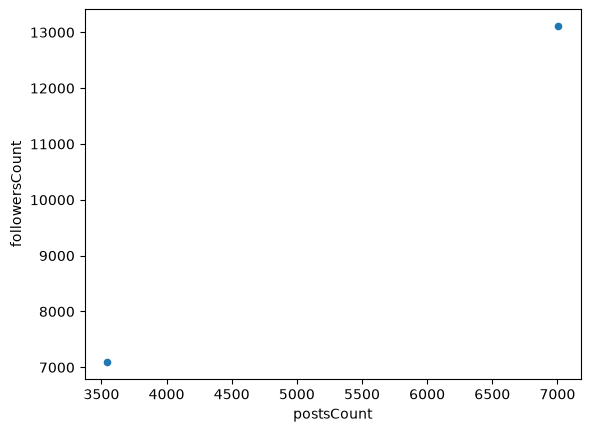

In [76]:
df.plot(kind='scatter', x='postsCount', y='followersCount')

## **Conclusions**
Based on this data, I have built support for my hypothesis, but it is very weak. By only having two accounts in my sample, there is not much to compare. I also realized another interesting insight as I did my project. That is, higher followers can actually mean lower engagement. Though this is something expected, it is still cool to prove!

## **Next Steps/Alternative Approaches**
My next steps are to run this test using a larger number of accounts. This would prove that my point is consistent. An alternative approach is to further break down this information and see how long accounts have been active. Then, how many posts/year correlate with gained followers/year.   

## AI Disclaimer- I used Claude to help me with this assignment. I use it to debug silly mistakes. I also got caught up first how to on how to merge the two different DataFrames and also needed help setting up my API requests.